# POD Tool Positive Cases & Failure Analysis
Analysing the instances where POD tools outperformed the baselines, and where they completely fail to identify a correct patch, to understand if there are any specific patterns.

In [1]:
from pathlib import Path
import pandas as pd
import json
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)

dataset = "petke_8h_figures"
# dataset = "repairllama_dedup_figures"

FIGURES_DIR = Path("bug_characteristics_figures") / dataset
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df_table = pd.read_csv(Path(f"../figure_replication/{dataset}/tables/rq3/rs-combined.csv"))
df_table = df_table.iloc[:-1] # drop Overall row

# Extract project, bug ID, and correct/overfitting patch counts from the "Bug" column.
bug_details = df_table["Bug"].str.extract(r"^(?P<Project>.+)-(?P<Bug_ID>\d+) \((?P<correct>\d+):(?P<overfitting>\d+)\)$")
df_table["Project"] = bug_details["Project"]
df_table["Bug_ID"] = bug_details["Bug_ID"].astype(int)
df_table["patch_num_correct"] = bug_details["correct"].astype(int)
df_table["patch_num_overfitting"] = bug_details["overfitting"].astype(int)
df_table["patch_num_total"] = df_table["patch_num_correct"] + df_table["patch_num_overfitting"]
df_table["correct_ratio"] = df_table["patch_num_correct"] / df_table["patch_num_total"]

# Load Defects4J bug metadata and merge
with open(Path('./defects4j-bugs.json'), encoding='utf-8') as f:
    bugs_raw = json.load(f)

df_bugs = pd.DataFrame([{
    'project': b['project'].lower(),
    'bug_id': b['bugId'],
    'repair_patterns': b.get('repairPatterns') or [],
    'lines_add': b['metrics']['linesAdd'],
    'lines_rem': b['metrics']['linesRem'],
    'lines_mod': b['metrics']['linesMod'],
    'n_methods': b['metrics']['methods'],
    'n_files': b['metrics']['files'],
    'n_chunks': b['metrics']['chunks'],
    # 'size_in_lines': b['metrics']['sizeInLines'],
    'first_exception': b['failingTests'][0]['error'].split(".")[-1] if b.get('failingTests') else None,
} for b in bugs_raw])

df_bugs['size_in_lines'] = df_bugs['lines_add'] + df_bugs['lines_rem'] + (2 * df_bugs['lines_mod'])

df_table['_project_key'] = df_table['Project'].str.lower()
df_table = df_table.merge(
    df_bugs,
    left_on=['_project_key', 'Bug_ID'],
    right_on=['project', 'bug_id'],
    how='left',
    validate='m:1',
).drop(columns=['project', 'bug_id', '_project_key'])

df_table

,Bug,entropy_delta,Invalidator,FIXCHECK,LLM4PatchCorrectness,DL4PatchCorrectness,RS-85,RS-95,Project,Bug_ID,patch_num_correct,patch_num_overfitting,patch_num_total,correct_ratio,repair_patterns,lines_add,lines_rem,lines_mod,n_methods,n_files,n_chunks,first_exception,size_in_lines
0,Chart-1 (8:21),2.0,22.0,NaN,8.0,NaN,6.0,8.0,Chart,1,8,21,29,0.275862,"[expLogicMod, singleLine]",0,0,1,1,1,1,AssertionFailedError,2
1,Chart-4 (5:1),1.0,1.0,2.0,NaN,NaN,2.0,2.0,Chart,4,5,1,6,0.833333,"[missNullCheckN, wrapsIf]",2,0,0,1,1,2,NullPointerException,2
2,Chart-7 (1:34),3.0,1.0,NaN,NaN,NaN,30.0,34.0,Chart,7,1,34,35,0.028571,"[copyPaste, expArithMod, wrongVarRef]",0,0,2,1,1,2,AssertionFailedError,4
3,Chart-8 (1:0),NaN,1.0,1.0,1.0,1.0,1.0,1.0,Chart,8,1,0,1,1.000000,"[initFix, singleLine, wrongVarRef]",0,0,1,1,1,1,AssertionFailedError,2
4,Chart-9 (1:10),NaN,11.0,11.0,NaN,4.0,10.0,11.0,Chart,9,1,10,11,0.090909,"[expLogicExpand, singleLine]",0,0,1,1,1,1,IllegalArgumentException,2
5,Chart-11 (3:0),1.0,1.0,1.0,1.0,NaN,1.0,1.0,Chart,11,3,0,3,1.000000,"[singleLine, wrongComp, wrongVarRef]",0,0,1,1,1,1,AssertionFailedError,2
6,Chart-20 (2:0),1.0,1.0,1.0,1.0,1.0,1.0,1.0,Chart,20,2,0,2,1.000000,"[initFix, singleLine, wrongVarRef]",0,0,1,1,1,1,AssertionFailedError,2
7,Chart-24 (3:0),NaN,1.0,NaN,1.0,NaN,1.0,1.0,Chart,24,3,0,3,1.000000,"[expArithMod, singleLine, wrongComp, wrongVarRef]",0,0,1,1,1,1,IllegalArgumentException,2
8,Closure-2 (1:2),NaN,3.0,3.0,3.0,NaN,3.0,3.0,Closure,2,1,2,3,0.333333,"[missNullCheckP, wrapsIfElse]",4,0,0,1,1,3,NullPointerException,4
9,Closure-14 (1:0),1.0,1.0,NaN,NaN,NaN,1.0,1.0,Closure,14,1,0,1,1.000000,"[constChange, singleLine, wrongVarRef]",0,0,1,1,1,1,AssertionFailedError,2


In [3]:
df_table.columns

Index(['Bug', 'entropy_delta', 'Invalidator', 'FIXCHECK',
       'LLM4PatchCorrectness', 'DL4PatchCorrectness', 'RS-85', 'RS-95',
       'Project', 'Bug_ID', 'patch_num_correct', 'patch_num_overfitting',
       'patch_num_total', 'correct_ratio', 'repair_patterns', 'lines_add',
       'lines_rem', 'lines_mod', 'n_methods', 'n_files', 'n_chunks',
       'first_exception', 'size_in_lines'],
      dtype='object')

## Characterizing Bugs Where POD Tools Beat Baselines / Completely Fail

For each POD tool, we systematically compare two subsets of bugs across patch count, correct-to-overfitting ratio, bug type (repair pattern), and project. Two analyses are run in sequence, reusing the same functions:

- **Positive cases**: bugs where the tool **beats** an RS baseline vs. bugs where the baseline **matches or beats** the tool.
- **N/A failure cases**: bugs where the tool **identifies at least one correct patch** vs. bugs where the tool **completely fails** (N/A entry in Table IV).

In [4]:
NUMERIC_CHARACTERISTIC_COLS = {
    'patch_num_correct': 'Correct Patches',
    'patch_num_overfitting': 'Overfitting Patches',
    'patch_num_total': 'Total Patches',
    'correct_ratio': 'Correct-to-Overfitting Ratio',
    'size_in_lines': 'Ground Truth Fix Size (LOC)',
    # 'n_methods': 'Bug Fix Size\n(methods)',
    # 'n_files': 'Files\nChanged',
    # 'n_chunks': 'Hunks',
}


def compare_with_nan_as_larger(a, b):
    if pd.isna(a):
        return False  # a treated as larger, so a < b is False
    if pd.isna(b):
        return True  # b treated as larger, so a < b is True
    return a < b


def get_comparison_groups(df, tool, baseline, mode):
    """Return (group_a, group_b, label_a, label_b) bug subsets for the requested analysis mode."""
    if mode == 'positive_cases':
        bugs_a = list(df.loc[df.apply(lambda row: compare_with_nan_as_larger(row[tool], row[baseline]), axis=1), 'Bug'])
        group_a = df[df['Bug'].isin(bugs_a)]
        group_b = df[~df['Bug'].isin(bugs_a)]
        return group_a, group_b, 'Beats', 'Does Not Beat'
    if mode == 'na_failure':
        group_a = df[df[tool].notna()]
        group_b = df[df[tool].isna()]
        return group_a, group_b, 'Non-N/A', 'N/A'
    raise ValueError(f"Unknown ANALYSIS_MODE: {mode!r}")


def summarize_numeric_characteristics(df_a, df_b, label_a='Beats', label_b='Does Not Beat', cols=NUMERIC_CHARACTERISTIC_COLS):
    """Mann-Whitney U comparison of numeric bug characteristics between the two groups."""
    rows = []
    for col in cols:
        a = df_a[col].dropna()
        b = df_b[col].dropna()
        if len(a) == 0 or len(b) == 0:
            continue
        u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        rank_biserial = 1 - (2 * u) / (len(a) * len(b))
        rows.append({
            'Metric': col,
            f'{label_a} median': a.median(),
            f'{label_b} median': b.median(),
            'Mann-Whitney U': u,
            'Rank-Biserial r': rank_biserial,
            'p-value': p,
            'Significant (p<0.05)': p < 0.05,
        })
    return pd.DataFrame(rows)


def summarize_categorical_characteristic(df_a, df_b, col, label_a='Beats', label_b='Does Not Beat'):
    """Chi-square comparison of a categorical bug characteristic between the two groups."""
    combined = pd.concat([
        df_a[[col]].assign(group=label_a),
        df_b[[col]].assign(group=label_b),
    ])
    contingency = pd.crosstab(combined[col], combined['group'])
    try:
        chi2, p, dof, _ = stats.chi2_contingency(contingency)
    except ValueError:
        chi2, p, dof = float('nan'), float('nan'), None
    return contingency, chi2, p, dof


def summarize_repair_patterns(df_a, df_b, label_a='Beats', label_b='Does Not Beat', min_count=3):
    """Chi-square comparison of repair pattern (bug type) frequency between the two groups."""
    def explode_patterns(df, group_label):
        d = df.dropna(subset=['repair_patterns']).copy()
        d = d.explode('repair_patterns').rename(columns={'repair_patterns': 'repair_pattern'})
        d = d[d['repair_pattern'].notna() & (d['repair_pattern'] != '')]
        d['group'] = group_label
        return d[['repair_pattern', 'group']]

    combined = pd.concat([
        explode_patterns(df_a, label_a),
        explode_patterns(df_b, label_b),
    ], ignore_index=True)

    pattern_counts = combined['repair_pattern'].value_counts()
    frequent_patterns = pattern_counts[pattern_counts >= min_count].index
    combined = combined[combined['repair_pattern'].isin(frequent_patterns)]
    if combined.empty:
        return pd.DataFrame(), float('nan'), float('nan'), None

    contingency = pd.crosstab(combined['repair_pattern'], combined['group'])
    try:
        chi2, p, dof, _ = stats.chi2_contingency(contingency)
    except ValueError:
        chi2, p, dof = float('nan'), float('nan'), None
    return contingency, chi2, p, dof


def plot_bug_characteristic_boxplots(df_a, df_b, tool, baseline, label_a='Beats', label_b='Does Not Beat', cols=NUMERIC_CHARACTERISTIC_COLS, save_name=None):
    """Box plots comparing numeric bug characteristics between the two groups."""
    fig, axes = plt.subplots(1, len(cols), figsize=(2.2 * len(cols), 4))
    for ax, (col, label) in zip(axes, cols.items()):
        data = [df_a[col].dropna().values, df_b[col].dropna().values]
        bp = ax.boxplot(data, showfliers=False, patch_artist=True)
        # ax.set_xticklabels([label_a, label_b], rotation=20, ha='right', fontsize=10)
        ax.set_xticklabels([label_a, label_b], fontsize=10)
        bp['boxes'][0].set_facecolor('gold')
        bp['boxes'][1].set_facecolor('darkviolet')
        ax.set_title(label, fontsize=8)
    # display_tool = pod_tools_display_names.get(tool, tool)
    # title_prefix = f'{display_tool} vs {baseline}' if baseline else display_tool
    # plt.suptitle(f'{title_prefix}: Bug Characteristics ({label_a} vs. {label_b})', fontsize=10)
    plt.tight_layout()
    if save_name:
        fig.savefig(FIGURES_DIR / f"{save_name}.png", dpi=300)
    plt.show()


def run_comparison_analysis(df, pod_tools, baselines, mode):
    """Run the tool/baseline comparison loop for the given mode and return the collected results."""
    numeric_results = []
    project_results = []
    exception_results = []
    pattern_results = []

    # Grouping in "na_failure" mode does not depend on the baseline, so only iterate over it once.
    baseline_iterable = baselines if mode == "positive_cases" else baselines[:1]

    for baseline in baseline_iterable:
        if mode == "positive_cases":
            print(f"{'='*80}\nComparing tools against {baseline}\n{'='*80}")
        else:
            print(f"{'='*80}\nComparing bugs with a correct-patch prediction vs. N/A failures\n{'='*80}")

        for tool in pod_tools:
            group_a, group_b, label_a, label_b = get_comparison_groups(df, tool, baseline, mode)
            baseline_label = baseline if mode == "positive_cases" else "-"

            print(f"\n--- {tool}: {label_a}={len(group_a)}, {label_b}={len(group_b)} (of {len(df)} bugs) ---")
            print(f"  {label_a} bugs: {group_a['Bug'].tolist()}")

            if len(group_a) < 2 or len(group_b) < 2:
                print("  Insufficient bugs in one group to run a statistical comparison; skipping.")
                continue

            numeric_summary = summarize_numeric_characteristics(group_a, group_b, label_a, label_b)
            numeric_summary.insert(0, 'Baseline', baseline_label)
            numeric_summary.insert(0, 'Tool', tool)
            numeric_results.append(numeric_summary)

            _, chi2_proj, p_proj, dof_proj = summarize_categorical_characteristic(group_a, group_b, 'Project', label_a, label_b)
            project_results.append({'Tool': tool, 'Baseline': baseline_label, 'chi2': chi2_proj, 'dof': dof_proj, 'p-value': p_proj})

            _, chi2_exc, p_exc, dof_exc = summarize_categorical_characteristic(group_a, group_b, 'first_exception', label_a, label_b)
            exception_results.append({'Tool': tool, 'Baseline': baseline_label, 'chi2': chi2_exc, 'dof': dof_exc, 'p-value': p_exc})

            _, chi2_pat, p_pat, dof_pat = summarize_repair_patterns(group_a, group_b, label_a, label_b)
            pattern_results.append({'Tool': tool, 'Baseline': baseline_label, 'chi2': chi2_pat, 'dof': dof_pat, 'p-value': p_pat})

            save_name = f"bug_characteristics_{dataset}_{mode}_{tool}" + (f"_{baseline}" if mode == "positive_cases" else "")
            plot_bug_characteristic_boxplots(group_a, group_b, tool, baseline if mode == "positive_cases" else None, f"{label_a}\n(n={len(group_a)})", f"{label_b}\n(n={len(group_b)})", save_name=save_name)
        print()

    return numeric_results, project_results, exception_results, pattern_results


def print_comparison_summary(numeric_results, project_results, exception_results, pattern_results, latex=False):
    """Print consolidated numeric/categorical summary tables for a completed comparison run."""
    df_numeric_results = pd.concat(numeric_results, ignore_index=True)
    df_project_results = pd.DataFrame(project_results)
    df_exception_results = pd.DataFrame(exception_results)
    df_pattern_results = pd.DataFrame(pattern_results)

    if not latex:
        print("Numeric bug characteristics (patch counts, ratio, complexity) by tool/baseline pair:")
        print(df_numeric_results.to_string(index=False))

        print("\nProject distribution comparison (chi-square) by tool/baseline pair:")
        print(df_project_results.to_string(index=False))

        print("\nFirst exception type distribution comparison (chi-square) by tool/baseline pair:")
        print(df_exception_results.to_string(index=False))

        print("\nRepair pattern (bug type) distribution comparison (chi-square) by tool/baseline pair:")
        print(df_pattern_results.to_string(index=False))

        print("\nStatistically significant numeric characteristics (p < 0.05):")
        print(df_numeric_results[df_numeric_results['Significant (p<0.05)']].to_string(index=False))
    else:
        print("\nLaTeX tables:")
        print("\nNumeric bug characteristics:")
        print(df_numeric_results.to_latex(index=False))

        print("\nProject distribution comparison:")
        print(df_project_results.to_latex(index=False))

        print("\nFirst exception type distribution comparison:")
        print(df_exception_results.to_latex(index=False))

        print("\nRepair pattern distribution comparison:")
        print(df_pattern_results.to_latex(index=False))

        print("\nStatistically significant numeric characteristics:")
        print(df_numeric_results[df_numeric_results['Significant (p<0.05)']].to_latex(index=False))

    return df_numeric_results, df_project_results, df_exception_results, df_pattern_results

In [5]:
pod_tools = [
    "entropy_delta",
    "Invalidator",
    "FIXCHECK",
    "LLM4PatchCorrectness",
    "DL4PatchCorrectness",
]

pod_tools_display_names = {
    "entropy_delta": "Yang et al.",
    "Invalidator": "Invalidator",
    "FIXCHECK": "FIXCHECK",
    "LLM4PatchCorrectness": "LLM4PatchCorrect",
    "DL4PatchCorrectness": "Tian et al.",
}

baselines = [
    "RS-85",
    "RS-95"
]

### Positive Cases: Bugs Where POD Tools Beat RS Baselines

Considering 29 bugs that had at least one correct and one overfitting patch.

Comparing tools against RS-85

--- entropy_delta: Beats=12, Does Not Beat=17 (of 29 bugs) ---
  Beats bugs: ['Chart-1 (8:21)', 'Chart-4 (5:1)', 'Chart-7 (1:34)', 'Lang-10 (3:7)', 'Lang-43 (2:2)', 'Lang-58 (1:53)', 'Lang-59 (4:25)', 'Math-53 (1:2)', 'Math-57 (2:2)', 'Math-70 (3:2)', 'Math-80 (1:47)', 'Math-82 (3:17)']


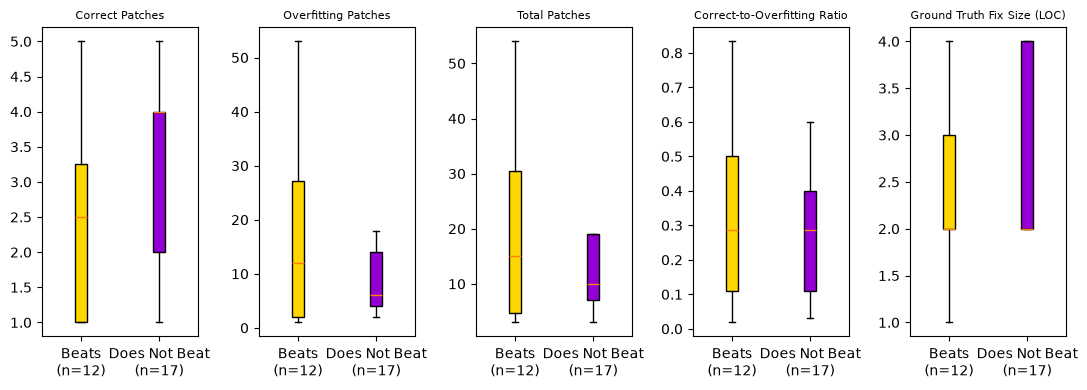


--- Invalidator: Beats=6, Does Not Beat=23 (of 29 bugs) ---
  Beats bugs: ['Chart-4 (5:1)', 'Chart-7 (1:34)', 'Lang-55 (5:8)', 'Lang-58 (1:53)', 'Lang-59 (4:25)', 'Math-80 (1:47)']


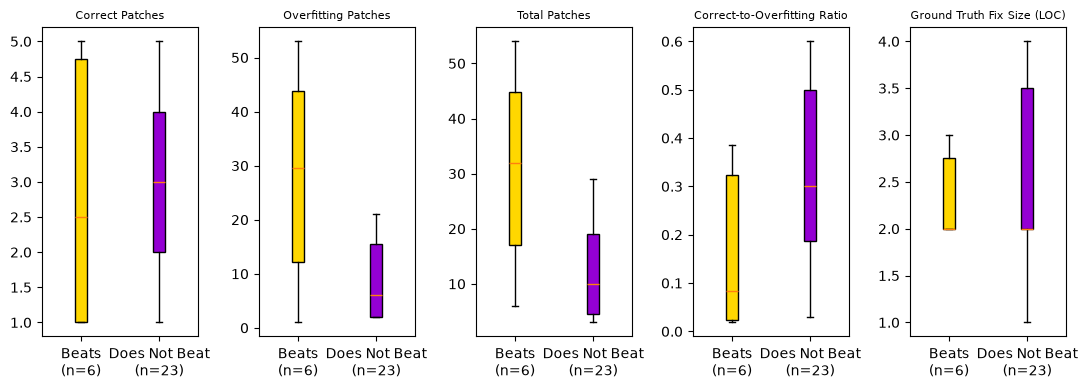


--- FIXCHECK: Beats=2, Does Not Beat=27 (of 29 bugs) ---
  Beats bugs: ['Math-33 (3:97)', 'Math-57 (2:2)']


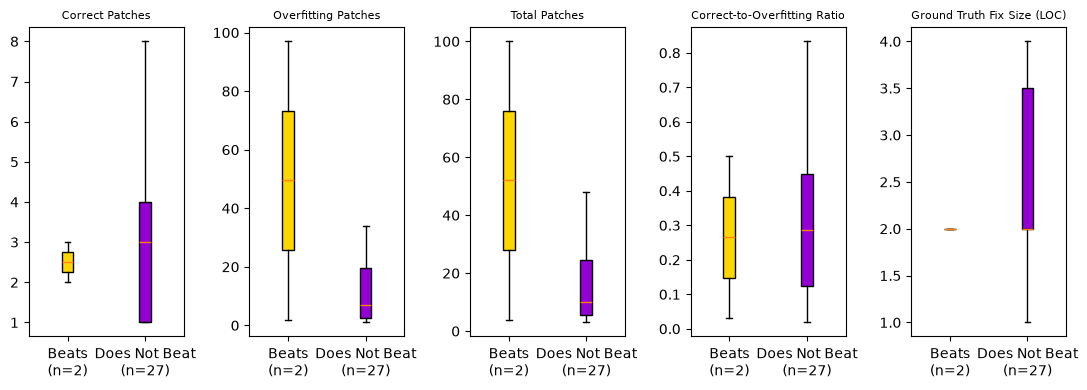


--- LLM4PatchCorrectness: Beats=11, Does Not Beat=18 (of 29 bugs) ---
  Beats bugs: ['Closure-46 (4:6)', 'Closure-126 (5:14)', 'Lang-43 (2:2)', 'Lang-57 (5:5)', 'Lang-59 (4:25)', 'Math-30 (4:6)', 'Math-57 (2:2)', 'Math-58 (1:18)', 'Math-70 (3:2)', 'Math-82 (3:17)', 'Time-7 (4:4)']


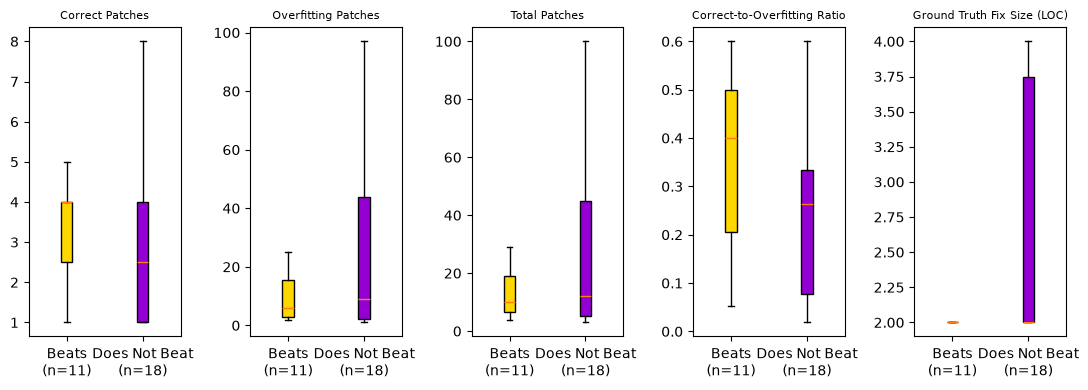


--- DL4PatchCorrectness: Beats=4, Does Not Beat=25 (of 29 bugs) ---
  Beats bugs: ['Chart-9 (1:10)', 'Lang-43 (2:2)', 'Math-53 (1:2)', 'Math-85 (4:51)']


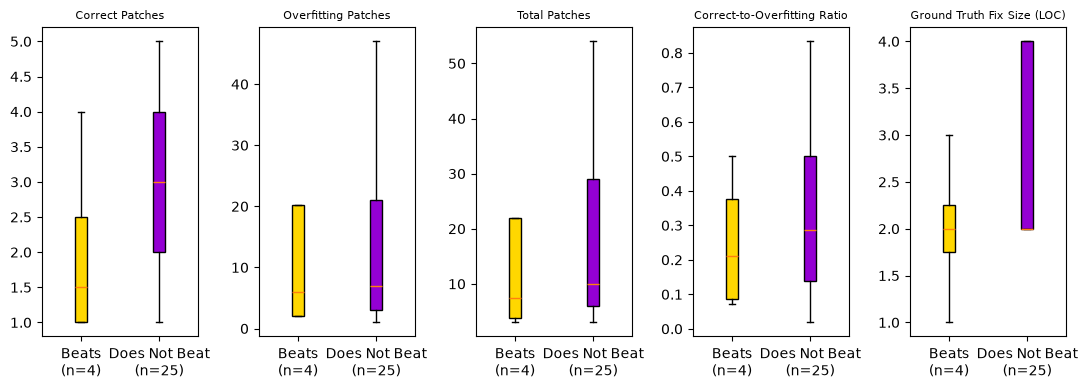


Comparing tools against RS-95

--- entropy_delta: Beats=13, Does Not Beat=16 (of 29 bugs) ---
  Beats bugs: ['Chart-1 (8:21)', 'Chart-4 (5:1)', 'Chart-7 (1:34)', 'Lang-10 (3:7)', 'Lang-33 (3:2)', 'Lang-43 (2:2)', 'Lang-58 (1:53)', 'Lang-59 (4:25)', 'Math-53 (1:2)', 'Math-57 (2:2)', 'Math-70 (3:2)', 'Math-80 (1:47)', 'Math-82 (3:17)']


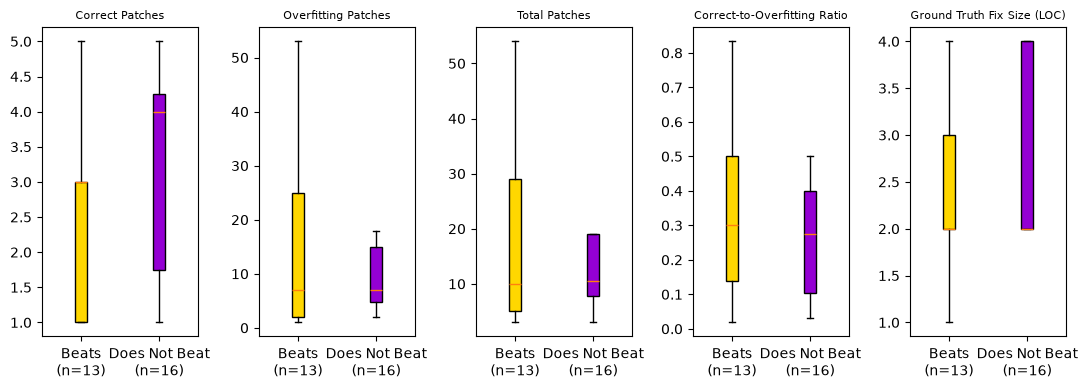


--- Invalidator: Beats=8, Does Not Beat=21 (of 29 bugs) ---
  Beats bugs: ['Chart-4 (5:1)', 'Chart-7 (1:34)', 'Lang-55 (5:8)', 'Lang-58 (1:53)', 'Lang-59 (4:25)', 'Math-58 (1:18)', 'Math-80 (1:47)', 'Math-85 (4:51)']


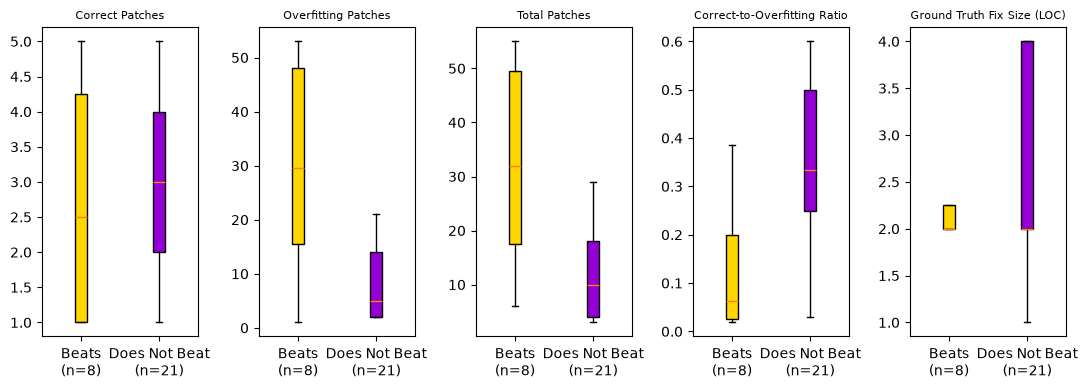


--- FIXCHECK: Beats=2, Does Not Beat=27 (of 29 bugs) ---
  Beats bugs: ['Math-33 (3:97)', 'Math-57 (2:2)']


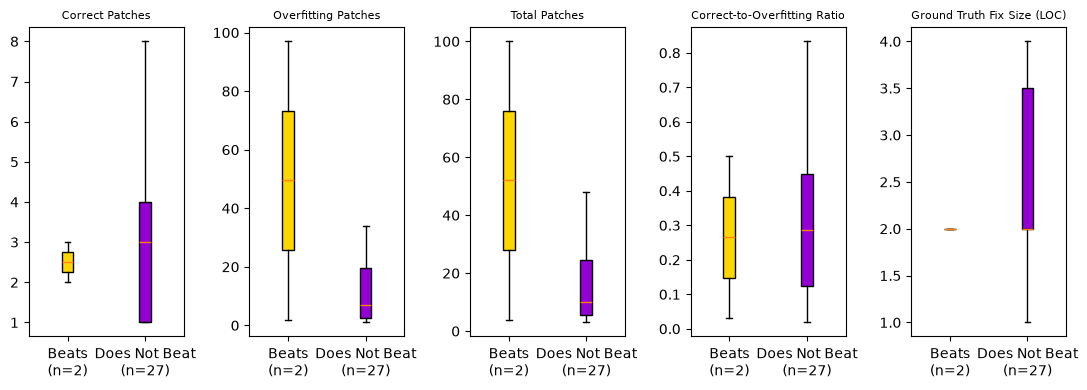


--- LLM4PatchCorrectness: Beats=11, Does Not Beat=18 (of 29 bugs) ---
  Beats bugs: ['Closure-46 (4:6)', 'Closure-126 (5:14)', 'Lang-43 (2:2)', 'Lang-57 (5:5)', 'Lang-59 (4:25)', 'Math-30 (4:6)', 'Math-57 (2:2)', 'Math-58 (1:18)', 'Math-70 (3:2)', 'Math-82 (3:17)', 'Time-7 (4:4)']


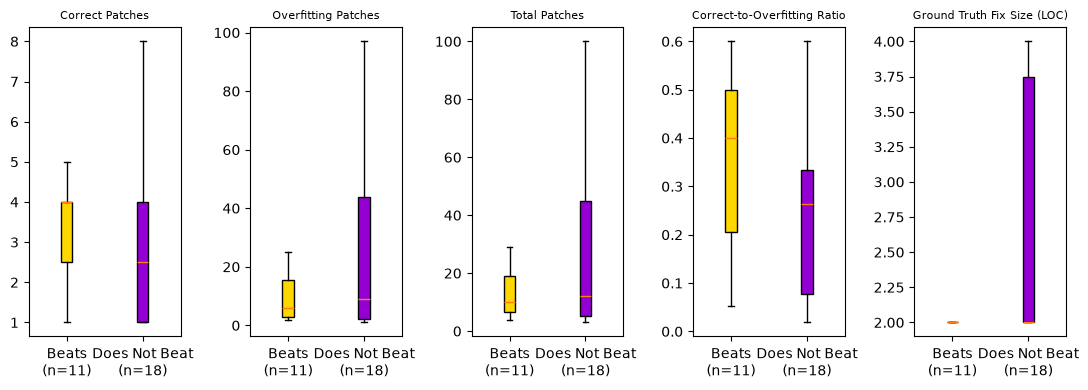


--- DL4PatchCorrectness: Beats=7, Does Not Beat=22 (of 29 bugs) ---
  Beats bugs: ['Chart-9 (1:10)', 'Lang-43 (2:2)', 'Math-50 (9:73)', 'Math-53 (1:2)', 'Math-70 (3:2)', 'Math-85 (4:51)', 'Time-7 (4:4)']


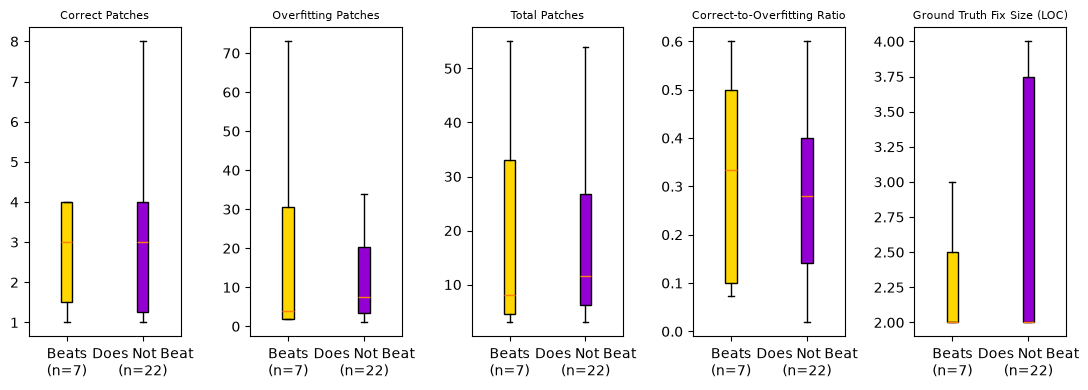

In [6]:
numeric_results_positive, project_results_positive, exception_results_positive, pattern_results_positive = run_comparison_analysis(
    df_table[df_table['patch_num_overfitting'] > 0], pod_tools, baselines, "positive_cases"
)

In [7]:
### Consolidated summary for paper: positive cases

df_numeric_positive, df_project_positive, df_exception_positive, df_pattern_positive = print_comparison_summary(
    numeric_results_positive, project_results_positive, exception_results_positive, pattern_results_positive
)

Numeric bug characteristics (patch counts, ratio, complexity) by tool/baseline pair:
                Tool Baseline                Metric  Beats median  Does Not Beat median  Mann-Whitney U  Rank-Biserial r  p-value  Significant (p<0.05)
       entropy_delta    RS-85     patch_num_correct      2.500000              4.000000            80.0         0.215686 0.331427                 False
       entropy_delta    RS-85 patch_num_overfitting     12.000000              6.000000            99.0         0.029412 0.911208                 False
       entropy_delta    RS-85       patch_num_total     15.000000             10.000000           103.5        -0.014706 0.964576                 False
       entropy_delta    RS-85         correct_ratio      0.287931              0.285714            99.0         0.029412 0.911603                 False
       entropy_delta    RS-85         size_in_lines      2.000000              2.000000            96.0         0.058824 0.773182                 False
   

#### Latex Tables

In [8]:
print_comparison_summary(
    numeric_results_positive, project_results_positive, exception_results_positive, pattern_results_positive, latex=True
)


LaTeX tables:

Numeric bug characteristics:
\begin{tabular}{lllrrrrrr}
\toprule
Tool & Baseline & Metric & Beats median & Does Not Beat median & Mann-Whitney U & Rank-Biserial r & p-value & Significant (p<0.05) \\
\midrule
entropy_delta & RS-85 & patch_num_correct & 2.500000 & 4.000000 & 80.000000 & 0.215686 & 0.331427 & False \\
entropy_delta & RS-85 & patch_num_overfitting & 12.000000 & 6.000000 & 99.000000 & 0.029412 & 0.911208 & False \\
entropy_delta & RS-85 & patch_num_total & 15.000000 & 10.000000 & 103.500000 & -0.014706 & 0.964576 & False \\
entropy_delta & RS-85 & correct_ratio & 0.287931 & 0.285714 & 99.000000 & 0.029412 & 0.911603 & False \\
entropy_delta & RS-85 & size_in_lines & 2.000000 & 2.000000 & 96.000000 & 0.058824 & 0.773182 & False \\
Invalidator & RS-85 & patch_num_correct & 2.500000 & 3.000000 & 64.000000 & 0.072464 & 0.804784 & False \\
Invalidator & RS-85 & patch_num_overfitting & 29.500000 & 6.000000 & 95.000000 & -0.376812 & 0.166677 & False \\
Invalidator 

(                    Tool Baseline                 Metric  Beats median  \
 0          entropy_delta    RS-85      patch_num_correct      2.500000   
 1          entropy_delta    RS-85  patch_num_overfitting     12.000000   
 2          entropy_delta    RS-85        patch_num_total     15.000000   
 3          entropy_delta    RS-85          correct_ratio      0.287931   
 4          entropy_delta    RS-85          size_in_lines      2.000000   
 5            Invalidator    RS-85      patch_num_correct      2.500000   
 6            Invalidator    RS-85  patch_num_overfitting     29.500000   
 7            Invalidator    RS-85        patch_num_total     32.000000   
 8            Invalidator    RS-85          correct_ratio      0.083251   
 9            Invalidator    RS-85          size_in_lines      2.000000   
 10              FIXCHECK    RS-85      patch_num_correct      2.500000   
 11              FIXCHECK    RS-85  patch_num_overfitting     49.500000   
 12              FIXCHECK

### N/A Failure Cases: Bugs Where POD Tools Completely Fail

Considering all 45 bugs which had at least one correct patch.

In [9]:
for tool in pod_tools:
    print("{} - Number of N/A cases: {}, {} of which for bugs with no overfitting patches.".format(pod_tools_display_names.get(tool, tool), df_table[[tool]].isna().sum().values[0], df_table[df_table["patch_num_overfitting"] == 0][[tool]].isna().sum().values[0]))

Yang et al. - Number of N/A cases: 9, 4 of which for bugs with no overfitting patches.
Invalidator - Number of N/A cases: 1, 1 of which for bugs with no overfitting patches.
FIXCHECK - Number of N/A cases: 13, 3 of which for bugs with no overfitting patches.
LLM4PatchCorrect - Number of N/A cases: 21, 7 of which for bugs with no overfitting patches.
Tian et al. - Number of N/A cases: 29, 10 of which for bugs with no overfitting patches.


Comparing bugs with a correct-patch prediction vs. N/A failures

--- entropy_delta: Non-N/A=36, N/A=9 (of 45 bugs) ---
  Non-N/A bugs: ['Chart-1 (8:21)', 'Chart-4 (5:1)', 'Chart-7 (1:34)', 'Chart-11 (3:0)', 'Chart-20 (2:0)', 'Closure-14 (1:0)', 'Closure-46 (4:6)', 'Closure-57 (2:2)', 'Closure-62 (4:14)', 'Closure-73 (2:0)', 'Closure-86 (1:0)', 'Closure-126 (5:14)', 'Lang-6 (1:0)', 'Lang-10 (3:7)', 'Lang-33 (3:2)', 'Lang-43 (2:2)', 'Lang-55 (5:8)', 'Lang-58 (1:53)', 'Lang-59 (4:25)', 'Math-5 (3:0)', 'Math-30 (4:6)', 'Math-33 (3:97)', 'Math-53 (1:2)', 'Math-57 (2:2)', 'Math-59 (2:0)', 'Math-65 (1:0)', 'Math-70 (3:2)', 'Math-75 (3:0)', 'Math-79 (1:3)', 'Math-80 (1:47)', 'Math-82 (3:17)', 'Math-85 (4:51)', 'Math-89 (3:0)', 'Mockito-29 (2:5)', 'Mockito-38 (4:0)', 'Time-7 (4:4)']


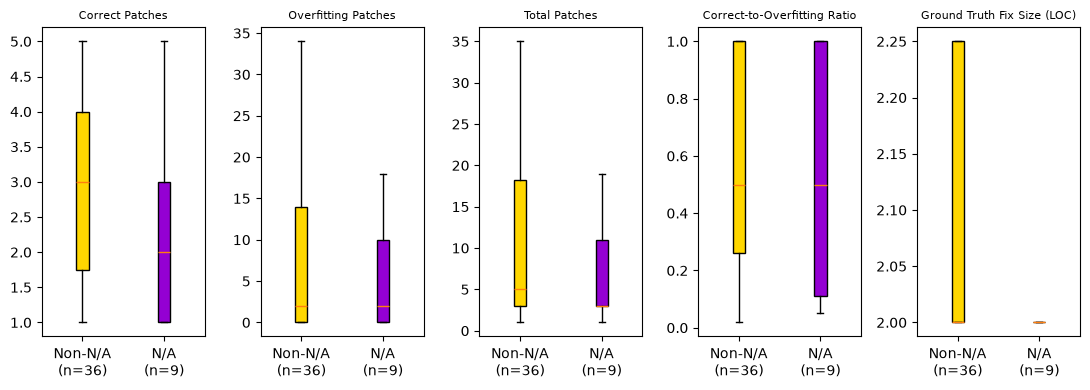


--- Invalidator: Non-N/A=44, N/A=1 (of 45 bugs) ---
  Non-N/A bugs: ['Chart-1 (8:21)', 'Chart-4 (5:1)', 'Chart-7 (1:34)', 'Chart-8 (1:0)', 'Chart-9 (1:10)', 'Chart-11 (3:0)', 'Chart-20 (2:0)', 'Chart-24 (3:0)', 'Closure-2 (1:2)', 'Closure-14 (1:0)', 'Closure-46 (4:6)', 'Closure-57 (2:2)', 'Closure-62 (4:14)', 'Closure-73 (2:0)', 'Closure-86 (1:0)', 'Closure-126 (5:14)', 'Lang-6 (1:0)', 'Lang-10 (3:7)', 'Lang-33 (3:2)', 'Lang-43 (2:2)', 'Lang-55 (5:8)', 'Lang-57 (5:5)', 'Lang-58 (1:53)', 'Lang-59 (4:25)', 'Math-5 (3:0)', 'Math-11 (3:0)', 'Math-30 (4:6)', 'Math-33 (3:97)', 'Math-34 (2:0)', 'Math-50 (9:73)', 'Math-53 (1:2)', 'Math-57 (2:2)', 'Math-58 (1:18)', 'Math-59 (2:0)', 'Math-70 (3:2)', 'Math-75 (3:0)', 'Math-79 (1:3)', 'Math-80 (1:47)', 'Math-82 (3:17)', 'Math-85 (4:51)', 'Math-89 (3:0)', 'Mockito-29 (2:5)', 'Mockito-38 (4:0)', 'Time-7 (4:4)']
  Insufficient bugs in one group to run a statistical comparison; skipping.

--- FIXCHECK: Non-N/A=32, N/A=13 (of 45 bugs) ---
  Non-N/A bu

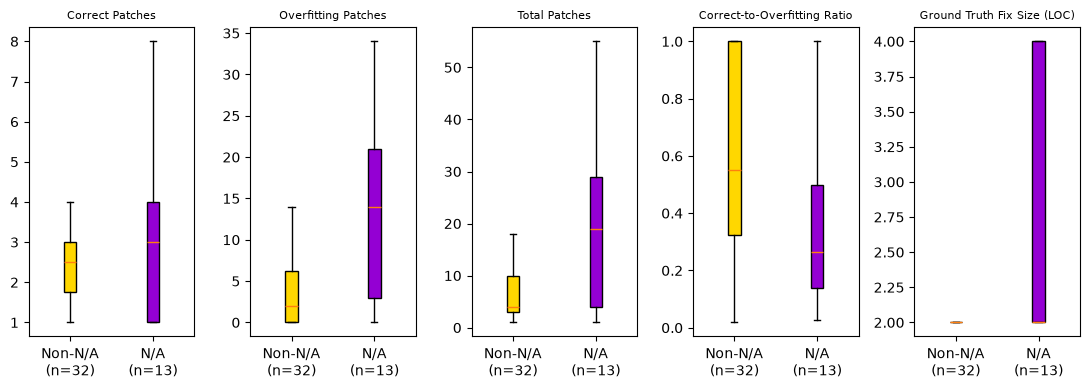


--- LLM4PatchCorrectness: Non-N/A=24, N/A=21 (of 45 bugs) ---
  Non-N/A bugs: ['Chart-1 (8:21)', 'Chart-8 (1:0)', 'Chart-11 (3:0)', 'Chart-20 (2:0)', 'Chart-24 (3:0)', 'Closure-2 (1:2)', 'Closure-46 (4:6)', 'Closure-73 (2:0)', 'Closure-126 (5:14)', 'Lang-6 (1:0)', 'Lang-33 (3:2)', 'Lang-43 (2:2)', 'Lang-57 (5:5)', 'Lang-59 (4:25)', 'Math-11 (3:0)', 'Math-30 (4:6)', 'Math-50 (9:73)', 'Math-57 (2:2)', 'Math-58 (1:18)', 'Math-59 (2:0)', 'Math-65 (1:0)', 'Math-70 (3:2)', 'Math-82 (3:17)', 'Time-7 (4:4)']


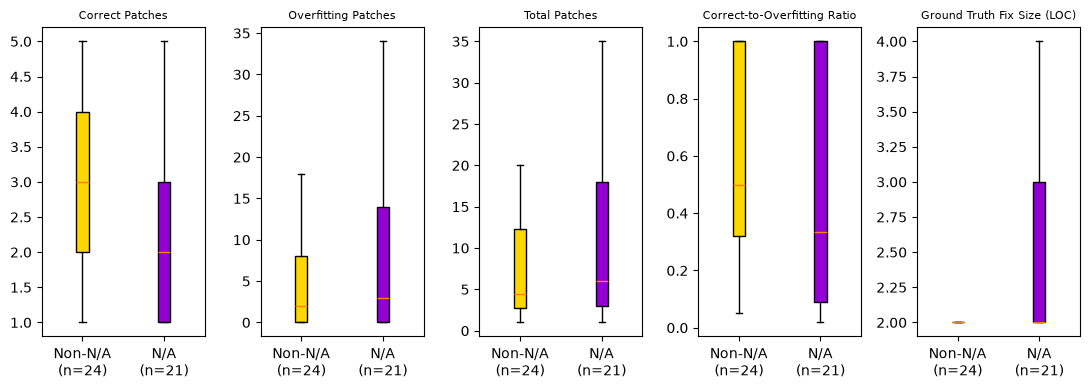


--- DL4PatchCorrectness: Non-N/A=16, N/A=29 (of 45 bugs) ---
  Non-N/A bugs: ['Chart-8 (1:0)', 'Chart-9 (1:10)', 'Chart-20 (2:0)', 'Closure-62 (4:14)', 'Closure-73 (2:0)', 'Lang-6 (1:0)', 'Lang-33 (3:2)', 'Lang-43 (2:2)', 'Lang-55 (5:8)', 'Math-34 (2:0)', 'Math-50 (9:73)', 'Math-53 (1:2)', 'Math-70 (3:2)', 'Math-85 (4:51)', 'Math-89 (3:0)', 'Time-7 (4:4)']


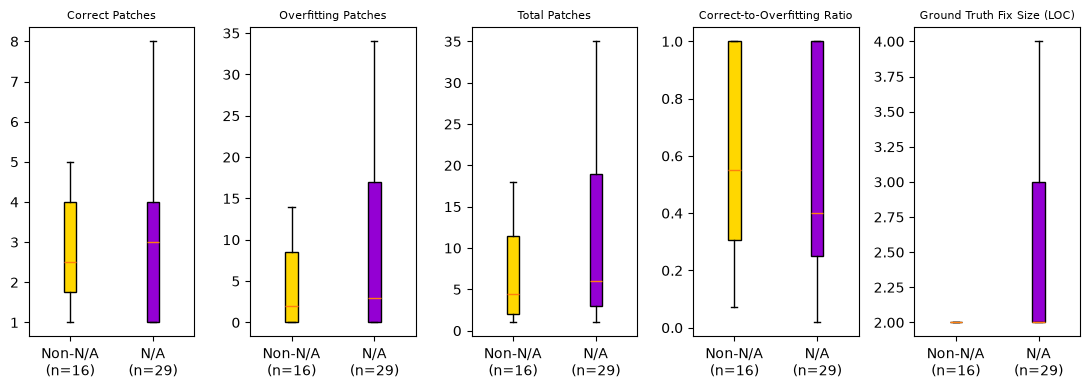

In [10]:
numeric_results_na, project_results_na, exception_results_na, pattern_results_na = run_comparison_analysis(
    df_table, pod_tools, baselines, "na_failure"
)

In [11]:
### Consolidated summary for paper: N/A failure cases

df_numeric_na, df_project_na, df_exception_na, df_pattern_na = print_comparison_summary(
    numeric_results_na, project_results_na, exception_results_na, pattern_results_na
)

Numeric bug characteristics (patch counts, ratio, complexity) by tool/baseline pair:
                Tool Baseline                Metric  Non-N/A median  N/A median  Mann-Whitney U  Rank-Biserial r  p-value  Significant (p<0.05)
       entropy_delta        -     patch_num_correct            3.00    2.000000           183.0        -0.129630 0.550984                 False
       entropy_delta        - patch_num_overfitting            2.00    2.000000           172.5        -0.064815 0.771111                 False
       entropy_delta        -       patch_num_total            5.00    3.000000           177.0        -0.092593 0.679279                 False
       entropy_delta        -         correct_ratio            0.50    0.500000           157.5         0.027778 0.907475                 False
       entropy_delta        -         size_in_lines            2.00    2.000000           164.0        -0.012346 0.956302                 False
            FIXCHECK        -     patch_num_correct

#### Latex Tables

In [12]:
print_comparison_summary(
    numeric_results_na, project_results_na, exception_results_na, pattern_results_na, latex=True
)


LaTeX tables:

Numeric bug characteristics:
\begin{tabular}{lllrrrrrr}
\toprule
Tool & Baseline & Metric & Non-N/A median & N/A median & Mann-Whitney U & Rank-Biserial r & p-value & Significant (p<0.05) \\
\midrule
entropy_delta & - & patch_num_correct & 3.000000 & 2.000000 & 183.000000 & -0.129630 & 0.550984 & False \\
entropy_delta & - & patch_num_overfitting & 2.000000 & 2.000000 & 172.500000 & -0.064815 & 0.771111 & False \\
entropy_delta & - & patch_num_total & 5.000000 & 3.000000 & 177.000000 & -0.092593 & 0.679279 & False \\
entropy_delta & - & correct_ratio & 0.500000 & 0.500000 & 157.500000 & 0.027778 & 0.907475 & False \\
entropy_delta & - & size_in_lines & 2.000000 & 2.000000 & 164.000000 & -0.012346 & 0.956302 & False \\
FIXCHECK & - & patch_num_correct & 2.500000 & 3.000000 & 183.000000 & 0.120192 & 0.529404 & False \\
FIXCHECK & - & patch_num_overfitting & 2.000000 & 14.000000 & 136.500000 & 0.343750 & 0.068320 & False \\
FIXCHECK & - & patch_num_total & 4.000000 & 19.00

(                    Tool Baseline                 Metric  Non-N/A median  \
 0          entropy_delta        -      patch_num_correct            3.00   
 1          entropy_delta        -  patch_num_overfitting            2.00   
 2          entropy_delta        -        patch_num_total            5.00   
 3          entropy_delta        -          correct_ratio            0.50   
 4          entropy_delta        -          size_in_lines            2.00   
 5               FIXCHECK        -      patch_num_correct            2.50   
 6               FIXCHECK        -  patch_num_overfitting            2.00   
 7               FIXCHECK        -        patch_num_total            4.00   
 8               FIXCHECK        -          correct_ratio            0.55   
 9               FIXCHECK        -          size_in_lines            2.00   
 10  LLM4PatchCorrectness        -      patch_num_correct            3.00   
 11  LLM4PatchCorrectness        -  patch_num_overfitting            2.00   